In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
ds_profile = pd.read_csv("../data/profile.csv")
ds_profile.columns = ["Year","DOY doy+dec. hours","hhmm","Ubatt","Ptemp","rh1","rh2","rh3","rh4","rh5","T1 8m","T2 4m","T3 2m","T4 1m","T5 0.5m","U1 8m",
                      "dd1","U2 4m","dd2","U3 2m","dd3","U4 1m","dd4","U5 0.5m","dd5"]
ds_iWS = pd.read_csv("../data/iws.csv")
ds_iWS.columns = ["Year","mm","dd","hh","minutes","doy","TC1avg","TC1std","TC2avg","TC2std","CJavg","xTSTR1","xTSTR2","xTSTR3","xTSTR4","xTSTR5",
                  "xTSTR6","xTSTR7","xTSTR8","THUTavg","RHWavg","RHTavg","HWSavg","HWSstd","HWSmax","HWDavg","VWSavg","VWSstd","NRUavg","NRUstd",
                  "NRLavg","NRIUavg","NRILavg","NRTavg","NRUcal","NRLcal","NRIUcal","NRILcal","NRID","BAP","SSH","xADW","xTBRG","MCH","TILTX",
                  "TILTY","LON","LAT","HMSL","PACC","SATS","spare 1","spare 2","VBAT","IDENTIFIER","STATUS","iwsID","xID","xTC1avg","xTC2avg",
                  "xCJavg","xTHUTavg","xRHWavg","xRHTavg","xHWSavg","xHWDavg","xVWSavg","xSSH","xSPARE1","xVBAT"]          
ds_CNR1 = pd.read_csv("../data/cnr1.csv")
ds_CNR1.columns = ["Year","doy","hhmm","SWTop_Avg","SWBottom_Avg","LWTop_Avg","LWBottom_Avg","cnr1_T_C_Avg","cnr1_T_K_Avg","LWTopC_Avg",
                   "LWBottomC_Avg","Rs_net_Avg","Rl_net_Avg","albedo_Avg","Rn_Avg","LWTopC_Avg_biased","LWBottomC_Avg_biased"]
ds_Flux = pd.read_csv("../data/turb.csv")
ds_Flux.columns = ["jaar","DOY","hhmm","uu","uv","uw","uTs","uTc1","uH2O","vv","vw","vTs","vTc1","vH2O","ww","wTs","wTc1","wH2O","std Ts","std Tc1",
                   "std","u","v","w","Ts","Tc1","H2O","u","dd","std dd","ww","wu","wTc2","uw","uTc2","TcTc2","w","u","Tc2","dd"]

In [3]:
#creating timestamps instead of days with decimal hours, with 30 minutes interval between measure points
ds_profile["datetime"] = pd.to_datetime("2026-01-01")+pd.to_timedelta(ds_profile["DOY doy+dec. hours"]-1,unit="D").dt.round("min")

ds_iWS["datetime"] = (pd.to_datetime(ds_iWS[["Year", "mm", "dd"]].rename(columns={"Year": "year", "mm": "month", "dd": "day"}))
    + pd.to_timedelta(ds_iWS["hh"], unit="h")
    + pd.to_timedelta(ds_iWS["minutes"], unit="m")
    + pd.to_timedelta(2, unit="h"))                     #iWS logs in UTC, the other loggers in CEST (UTC+2)
ds_iWS = ds_iWS.loc[ds_iWS["datetime"] >= "2026-09-15 15:30:00"]

ds_CNR1["datetime"] = pd.to_datetime("2026-01-01")+pd.to_timedelta(ds_CNR1["doy"]-1,unit="D").dt.round("min")
ds_CNR1 = ds_CNR1.loc[ds_CNR1["datetime"] >= "2026-09-15 15:30:00"]

ds_Flux["datetime"] = pd.to_datetime("2026-01-01")+pd.to_timedelta(ds_Flux["DOY"]-1,unit="D").dt.round("min")
ds_Flux = ds_Flux.loc[ds_Flux["datetime"] >= "2026-09-15 15:30:00"]

In [4]:
print("length profile:",len(ds_profile),"of which amount of NaN:",ds_profile[["T1 8m","T2 4m","T3 2m","T4 1m","T5 0.5m"]].isna().sum())
print("-----")
print("length iWS:",len(ds_iWS),"of which amount of NaN:",ds_iWS[["TC1avg","TC2avg"]].isna().sum())
print("-----")
print("length CNR1:",len(ds_CNR1),"of which amount of NaN:",ds_CNR1["cnr1_T_C_Avg"].isna().sum())
print("-----")
print("length Flux:",len(ds_Flux),"of which amount of NaN:",ds_Flux[["Ts","Tc1"]].isna().sum())

length profile: 1298 of which amount of NaN: T1 8m      0
T2 4m      0
T3 2m      0
T4 1m      0
T5 0.5m    0
dtype: int64
-----
length iWS: 1272 of which amount of NaN: TC1avg    0
TC2avg    0
dtype: int64
-----
length CNR1: 1296 of which amount of NaN: 1
-----
length Flux: 1296 of which amount of NaN: Ts       7
Tc1    560
dtype: int64


In [5]:
time_profile = ds_profile["datetime"]
time_iWS = ds_iWS["datetime"]
time_CNR1 = ds_CNR1["datetime"]
time_Flux = ds_Flux["datetime"]

In [6]:
temp_vaisala_8m = ds_profile["T1 8m"]
temp_vaisala_4m = ds_profile["T2 4m"]
temp_vaisala_2m = ds_profile["T3 2m"]
temp_vaisala_1m = ds_profile["T4 1m"]
temp_vaisala_05m = ds_profile["T5 0.5m"]

temp_tc1 = ds_iWS["TC1avg"]
temp_tc2 = ds_iWS["TC2avg"]

temp_cnr1 = ds_CNR1["cnr1_T_C_Avg"]

temp_anemometer = ds_Flux["Ts"]                      #temperature deduced from sonic anemometer data
temp_tc_anemometer = ds_Flux[["datetime","Tc1"]]     #temperature measured by thermocouple close to sonic anemometer
print(len(temp_tc_anemometer))
temp_tc_anemometer = temp_tc_anemometer.dropna()
temp_tc_anemometer = temp_tc_anemometer.loc[temp_tc_anemometer["datetime"] <= "2026-09-27 15:30:00"]
time_tc_anemometer = temp_tc_anemometer["datetime"]
temp_tc_anemometer = temp_tc_anemometer["Tc1"]
print(len(time_tc_anemometer))

1296
564


Text(0.5, 1.0, 'Sonic Anemometer')

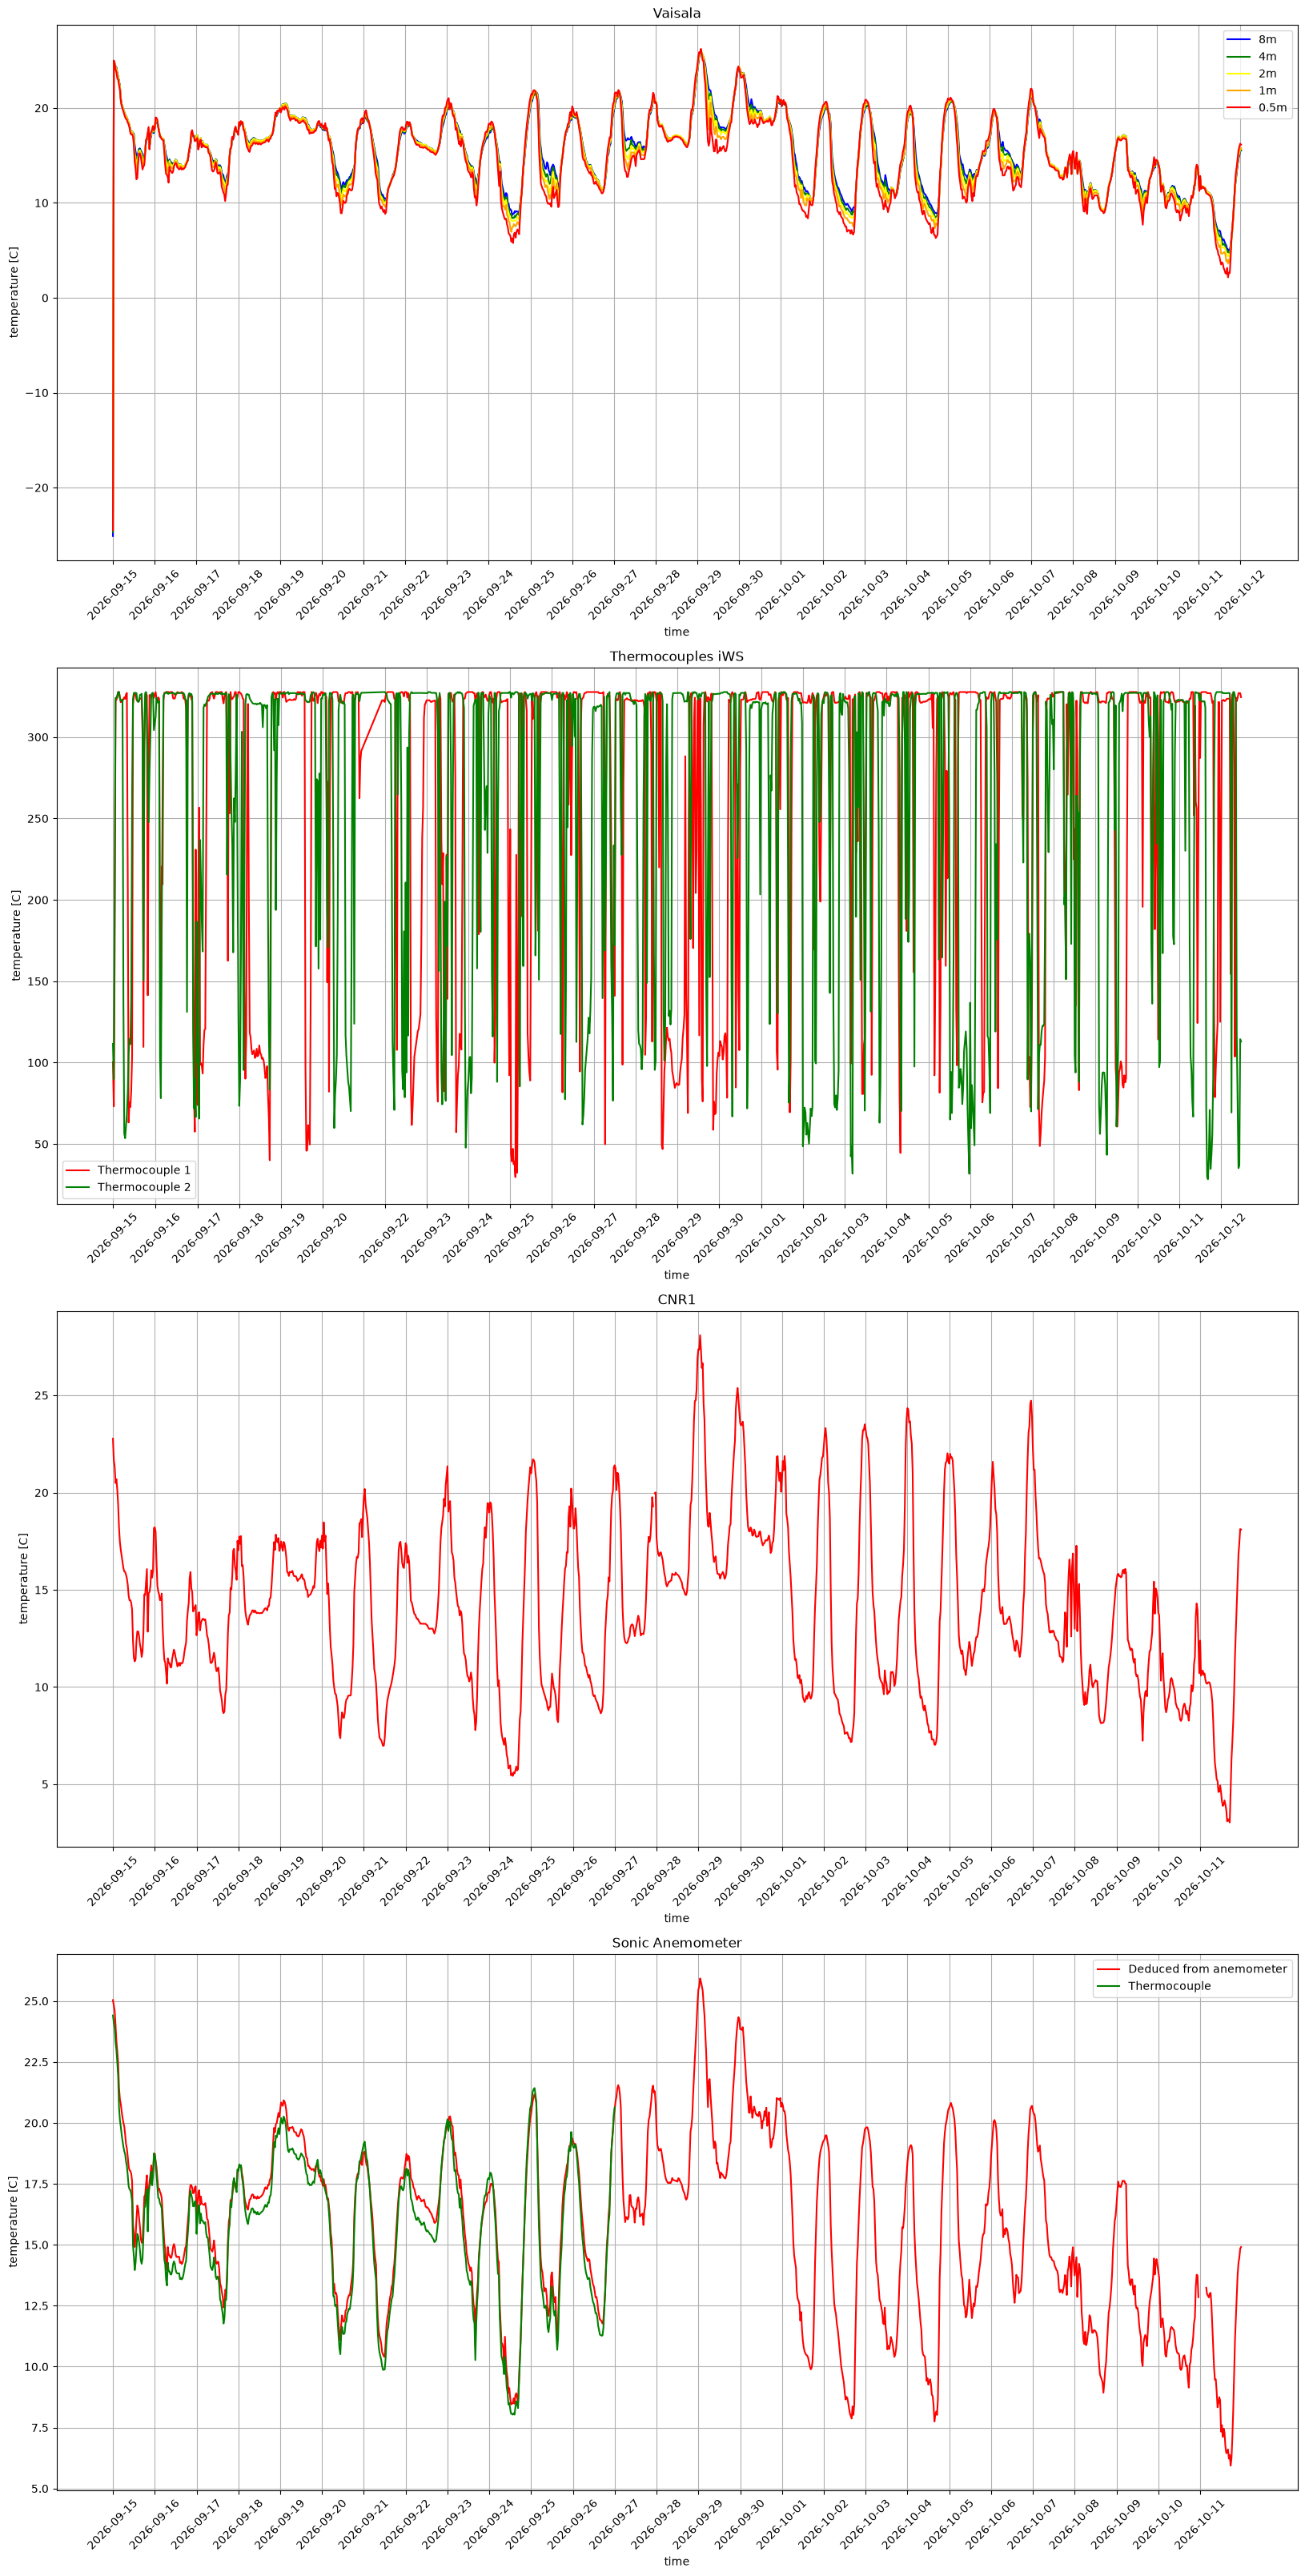

In [7]:
plt.figure(figsize=[20,40])
plt.subplot(4,1,1)
plt.plot(time_profile,temp_vaisala_8m,c="blue",label="8m")
plt.plot(time_profile,temp_vaisala_4m,c="green",label="4m")
plt.plot(time_profile,temp_vaisala_2m,c="yellow",label="2m")
plt.plot(time_profile,temp_vaisala_1m,c="orange",label="1m")
plt.plot(time_profile,temp_vaisala_05m,c="red",label="0.5m")
plt.legend()
plt.grid()
plt.xticks(time_profile[::48],rotation=45)
plt.xlabel("time")
plt.ylabel("temperature [C]")
plt.title("Vaisala")

plt.subplot(4,1,2)
plt.plot(time_iWS,temp_tc1,c="red",label="Thermocouple 1")
plt.plot(time_iWS,temp_tc2,c="green",label="Thermocouple 2")
plt.legend()
plt.grid()
plt.xticks(time_iWS[::48],rotation=45)
plt.xlabel("time")
plt.ylabel("temperature [C]")
plt.title("Thermocouples iWS")

plt.subplot(4,1,3)
plt.plot(time_CNR1,temp_cnr1,c="red")
plt.grid()
plt.xticks(time_CNR1[::48],rotation=45)
plt.xlabel("time")
plt.ylabel("temperature [C]")
plt.title("CNR1")

plt.subplot(4,1,4)
plt.plot(time_Flux,temp_anemometer,c="red",label="Deduced from anemometer")
plt.plot(time_tc_anemometer,temp_tc_anemometer,c="green",label="Thermocouple")
plt.legend()
plt.grid()
plt.xticks(time_Flux[::48],rotation=45)
plt.xlabel("time")
plt.ylabel("temperature [C]")
plt.title("Sonic Anemometer")

In [8]:
# Profile mast wind speed and direction at five heights
ds_profile_wind = ds_profile[
    [
        "datetime",
        "U1 8m", "dd1",
        "U2 4m", "dd2",
        "U3 2m", "dd3",
        "U4 1m", "dd4",
        "U5 0.5m", "dd5",
    ]
].copy()

# iWS wind measurements
ds_iWS_wind = ds_iWS[
    ["datetime", "HWSavg", "HWSstd", "HWSmax", "HWDavg"]
].copy().rename(
    columns={
        "HWSavg": "wind_speed_avg",
        "HWSstd": "wind_speed_std",
        "HWSmax": "wind_speed_max",
        "HWDavg": "wind_direction_avg",
    }
)

# CNR1 shortwave radiation: top is incoming; bottom is outgoing
ds_shortwave = ds_CNR1[
    ["datetime", "SWTop_Avg", "SWBottom_Avg"]
].copy().rename(
    columns={
        "SWTop_Avg": "shortwave_in",
        "SWBottom_Avg": "shortwave_out",
    }
)

In [9]:
start_time = "2026-09-15 15:30:00"

# Profile mast wind speed and direction at five heights
ds_profile_wind = ds_profile[
    [
        "datetime",
        "U1 8m", "dd1",
        "U2 4m", "dd2",
        "U3 2m", "dd3",
        "U4 1m", "dd4",
        "U5 0.5m", "dd5",
    ]
].loc[lambda df: df["datetime"] >= start_time].copy()

# iWS wind measurements
ds_iWS_wind = ds_iWS[
    ["datetime", "HWSavg", "HWSstd", "HWSmax", "HWDavg"]
].loc[lambda df: df["datetime"] >= start_time].copy().rename(
    columns={
        "HWSavg": "wind_speed_avg",
        "HWSstd": "wind_speed_std",
        "HWSmax": "wind_speed_max",
        "HWDavg": "wind_direction_avg",
    }
)

# CNR1 shortwave radiation: top is incoming; bottom is outgoing
ds_shortwave = ds_CNR1[
    ["datetime", "SWTop_Avg", "SWBottom_Avg"]
].loc[lambda df: df["datetime"] >= start_time].copy().rename(
    columns={
        "SWTop_Avg": "shortwave_in",
        "SWBottom_Avg": "shortwave_out",
    }
)

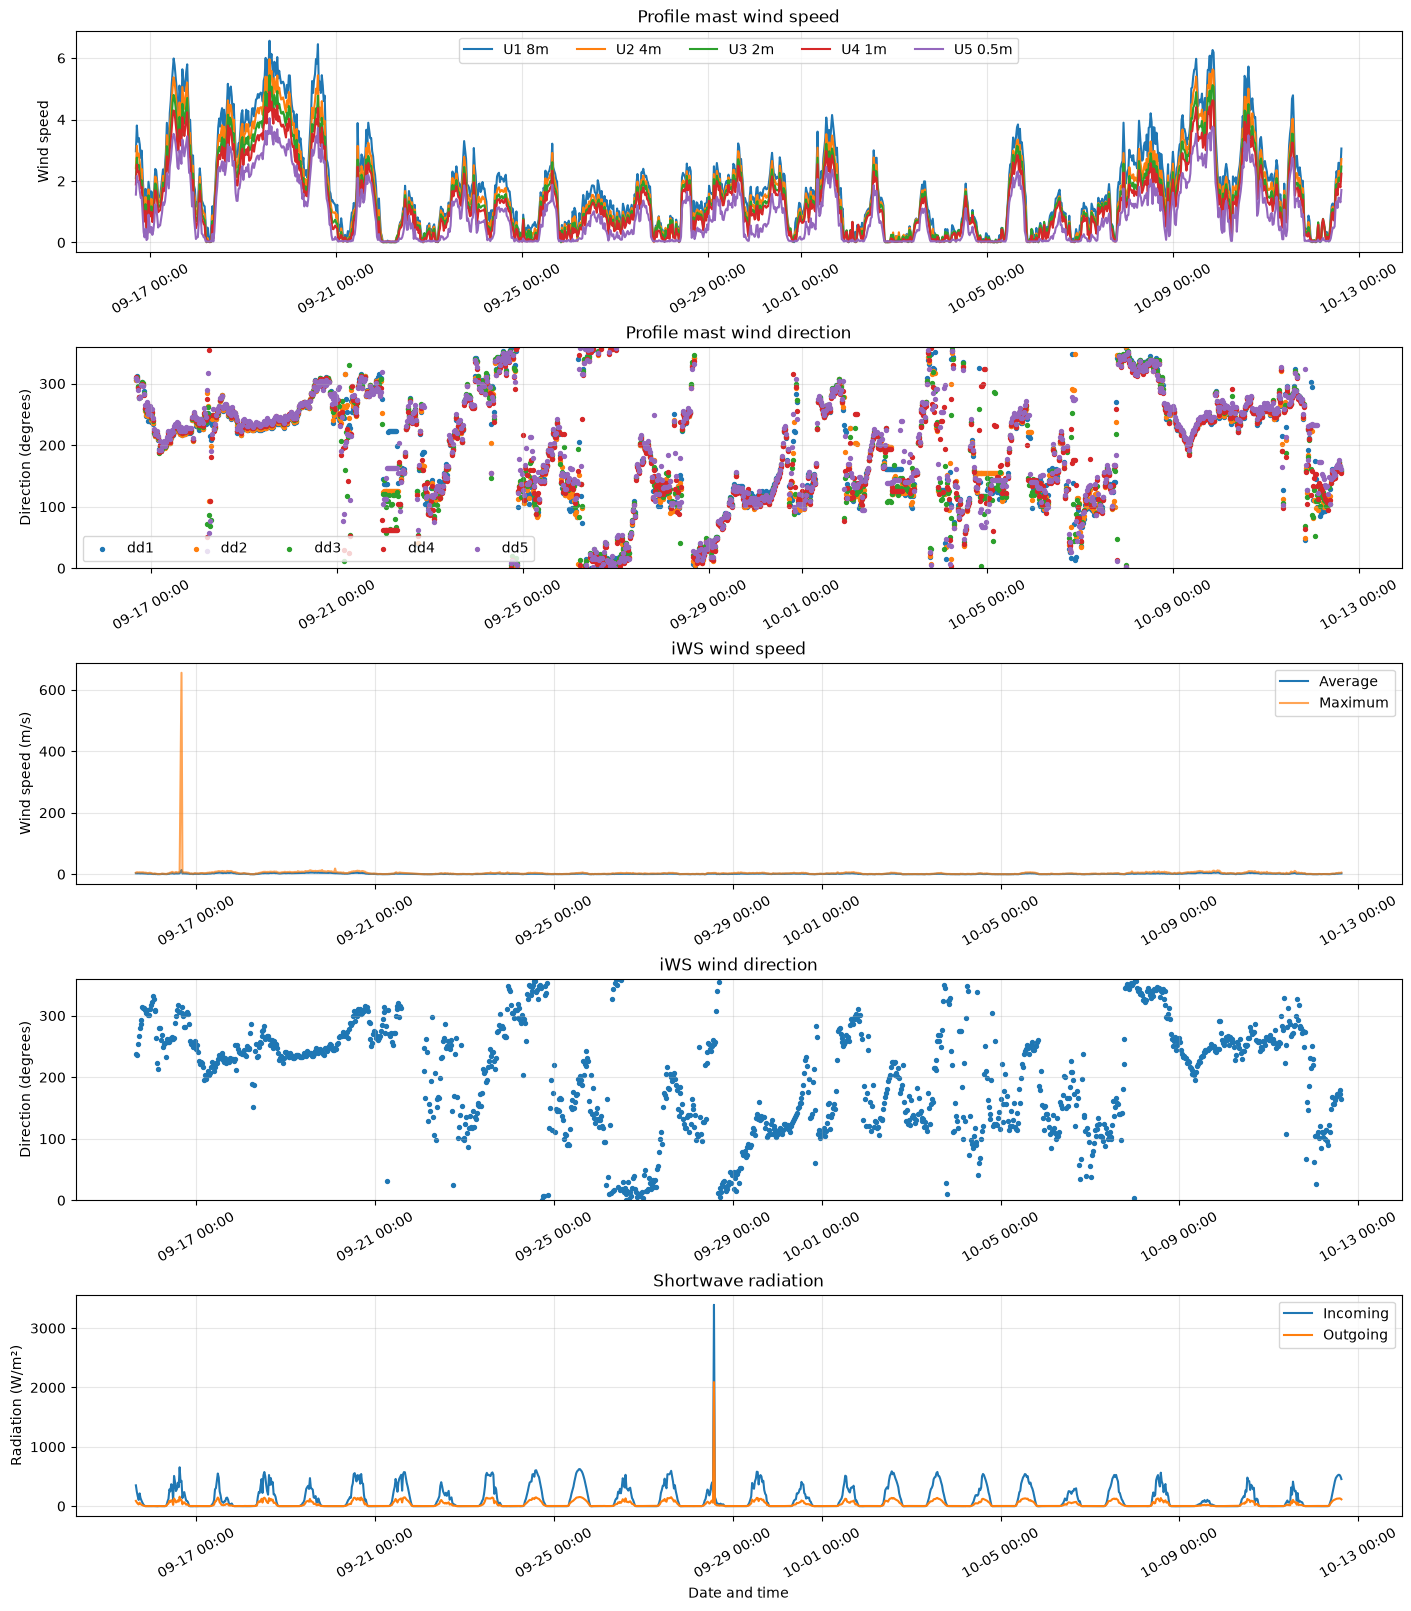

In [10]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

fig, axes = plt.subplots(5, 1, figsize=(14, 16), constrained_layout=True)

# Wind speed at the five profile mast heights
profile_speed_cols = ["U1 8m", "U2 4m", "U3 2m", "U4 1m", "U5 0.5m"]
for col in profile_speed_cols:
    axes[0].plot(ds_profile_wind["datetime"], ds_profile_wind[col], label=col)
axes[0].set_title("Profile mast wind speed")
axes[0].set_ylabel("Wind speed")
axes[0].legend(ncol=5)
axes[0].grid(True, alpha=0.3)

# Wind direction at the five heights; points avoid misleading lines across 0°/360°
profile_dir_cols = ["dd1", "dd2", "dd3", "dd4", "dd5"]
for col in profile_dir_cols:
    axes[1].scatter(
        ds_profile_wind["datetime"],
        ds_profile_wind[col],
        label=col,
        s=8,
    )
axes[1].set_title("Profile mast wind direction")
axes[1].set_ylabel("Direction (degrees)")
axes[1].set_ylim(0, 360)
axes[1].legend(ncol=5)
axes[1].grid(True, alpha=0.3)

# iWS wind speed
axes[2].plot(
    ds_iWS_wind["datetime"],
    ds_iWS_wind["wind_speed_avg"],
    label="Average",
)
axes[2].plot(
    ds_iWS_wind["datetime"],
    ds_iWS_wind["wind_speed_max"],
    label="Maximum",
    alpha=0.7,
)
axes[2].set_title("iWS wind speed")
axes[2].set_ylabel("Wind speed (m/s)")
axes[2].legend()
axes[2].grid(True, alpha=0.3)

# iWS wind direction
axes[3].scatter(
    ds_iWS_wind["datetime"],
    ds_iWS_wind["wind_direction_avg"],
    s=8,
)
axes[3].set_title("iWS wind direction")
axes[3].set_ylabel("Direction (degrees)")
axes[3].set_ylim(0, 360)
axes[3].grid(True, alpha=0.3)

# Shortwave radiation
axes[4].plot(
    ds_shortwave["datetime"],
    ds_shortwave["shortwave_in"],
    label="Incoming",
)
axes[4].plot(
    ds_shortwave["datetime"],
    ds_shortwave["shortwave_out"],
    label="Outgoing",
)
axes[4].set_title("Shortwave radiation")
axes[4].set_ylabel("Radiation (W/m²)")
axes[4].set_xlabel("Date and time")
axes[4].legend()
axes[4].grid(True, alpha=0.3)

for ax in axes:
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%m-%d %H:%M"))
    ax.tick_params(axis="x", rotation=30)

plt.show()

wind_speed_avg: flagged 42 of 1272 values
wind_speed_max: flagged 32 of 1272 values
shortwave_in: flagged 48 of 1296 values
shortwave_out: flagged 17 of 1296 values


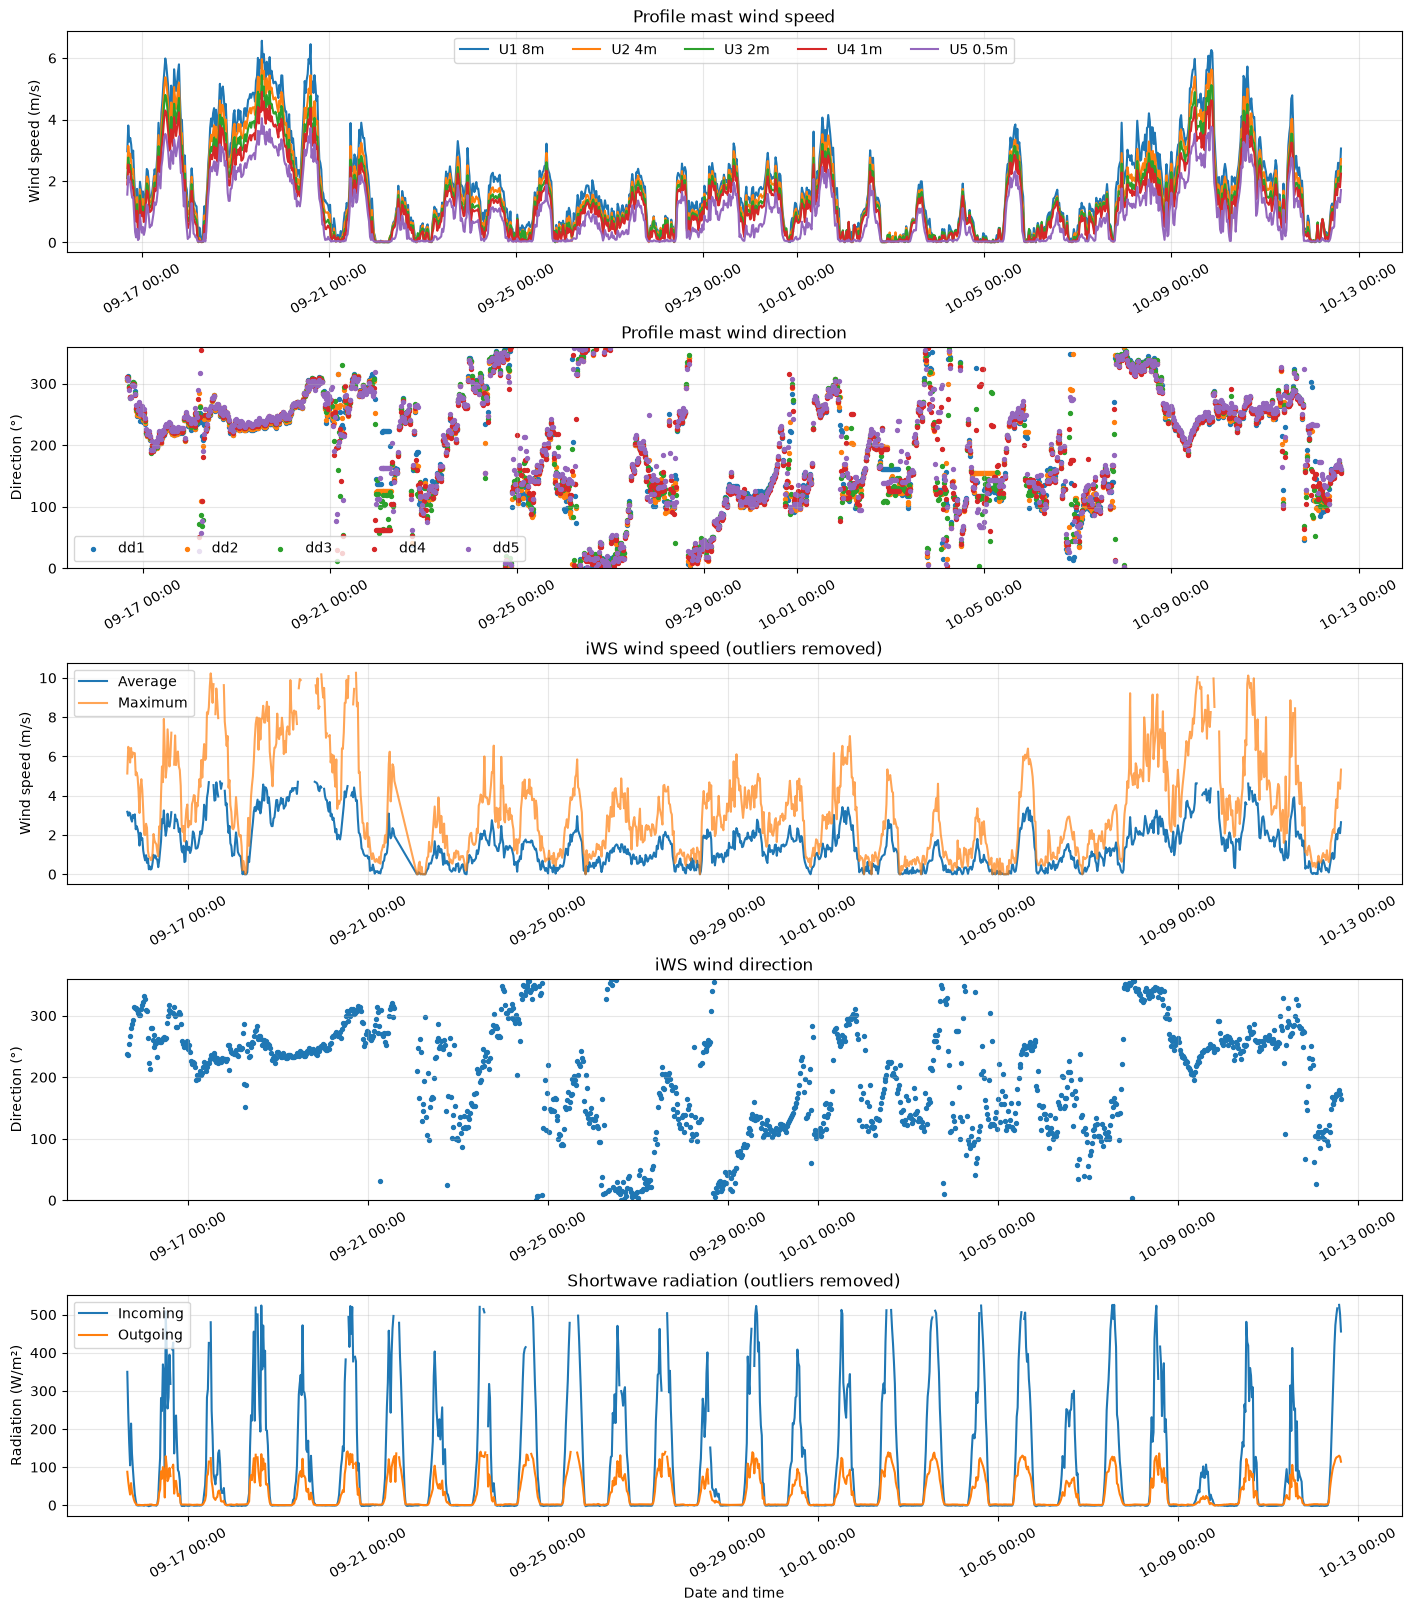

In [11]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

start_time = "2026-09-15 15:30:00"

# ---------- Select data ----------
ds_profile_wind = ds_profile[
    ["datetime",
     "U1 8m", "dd1", "U2 4m", "dd2", "U3 2m", "dd3",
     "U4 1m", "dd4", "U5 0.5m", "dd5"]
].loc[lambda df: df["datetime"] >= start_time].copy()

ds_iWS_wind = ds_iWS[
    ["datetime", "HWSavg", "HWSstd", "HWSmax", "HWDavg"]
].loc[lambda df: df["datetime"] >= start_time].copy().rename(columns={
    "HWSavg": "wind_speed_avg",
    "HWSstd": "wind_speed_std",
    "HWSmax": "wind_speed_max",
    "HWDavg": "wind_direction_avg",
})

# CNR1: top = incoming, bottom = outgoing
ds_shortwave = ds_CNR1[
    ["datetime", "SWTop_Avg", "SWBottom_Avg"]
].loc[lambda df: df["datetime"] >= start_time].copy().rename(columns={
    "SWTop_Avg": "shortwave_in",
    "SWBottom_Avg": "shortwave_out",
})

# ---------- Outlier removal (IQR) ----------
def iqr_outlier_mask(series, factor=1.5):
    q1, q3 = series.quantile(0.25), series.quantile(0.75)
    iqr = q3 - q1
    return (series < q1 - factor * iqr) | (series > q3 + factor * iqr)

iWS_clean = ds_iWS_wind.copy()
shortwave_clean = ds_shortwave.copy()

for df, cols in [(iWS_clean, ["wind_speed_avg", "wind_speed_max"]),
                 (shortwave_clean, ["shortwave_in", "shortwave_out"])]:
    for col in cols:
        mask = iqr_outlier_mask(df[col])
        print(f"{col}: flagged {mask.sum()} of {len(mask)} values")
        df.loc[mask, col] = float("nan")

# ---------- Plots ----------
fig, axes = plt.subplots(5, 1, figsize=(14, 16), constrained_layout=True)

# Profile mast wind speed
for col in ["U1 8m", "U2 4m", "U3 2m", "U4 1m", "U5 0.5m"]:
    axes[0].plot(ds_profile_wind["datetime"], ds_profile_wind[col], label=col)
axes[0].set_title("Profile mast wind speed")
axes[0].set_ylabel("Wind speed (m/s)")
axes[0].legend(ncol=5)

# Profile mast wind direction
for col in ["dd1", "dd2", "dd3", "dd4", "dd5"]:
    axes[1].scatter(ds_profile_wind["datetime"], ds_profile_wind[col], label=col, s=8)
axes[1].set_title("Profile mast wind direction")
axes[1].set_ylabel("Direction (°)")
axes[1].set_ylim(0, 360)
axes[1].legend(ncol=5)

# iWS wind speed (outliers removed)
axes[2].plot(iWS_clean["datetime"], iWS_clean["wind_speed_avg"], label="Average")
axes[2].plot(iWS_clean["datetime"], iWS_clean["wind_speed_max"], label="Maximum", alpha=0.7)
axes[2].set_title("iWS wind speed (outliers removed)")
axes[2].set_ylabel("Wind speed (m/s)")
axes[2].legend()

# iWS wind direction
axes[3].scatter(iWS_clean["datetime"], iWS_clean["wind_direction_avg"], s=8)
axes[3].set_title("iWS wind direction")
axes[3].set_ylabel("Direction (°)")
axes[3].set_ylim(0, 360)

# Shortwave radiation (outliers removed)
axes[4].plot(shortwave_clean["datetime"], shortwave_clean["shortwave_in"], label="Incoming")
axes[4].plot(shortwave_clean["datetime"], shortwave_clean["shortwave_out"], label="Outgoing")
axes[4].set_title("Shortwave radiation (outliers removed)")
axes[4].set_ylabel("Radiation (W/m²)")
axes[4].set_xlabel("Date and time")
axes[4].legend()

for ax in axes:
    ax.grid(True, alpha=0.3)
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%m-%d %H:%M"))
    ax.tick_params(axis="x", rotation=30)

plt.show()